In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # Para ejecutar también fuera de Colab.

carpetas = [Path('/content/drive/MyDrive/mineriaDatos'), Path('.'), Path('/mnt/data')]
archivos = [
    carpeta / nombre
    for carpeta in carpetas
    for nombre in ['online_shoppers_sin_duplicados.csv', 'online_shoppers_intention.csv']
]
archivo = next((p for p in archivos if p.exists()), None)
if archivo is None:
    raise FileNotFoundError('Sube online_shoppers_sin_duplicados.csv a la carpeta mineriaDatos de Drive.')

df = pd.read_csv(archivo)
if archivo.name == 'online_shoppers_intention.csv':
    df = df.drop_duplicates().reset_index(drop=True)

print('Archivo utilizado:', archivo)
print('Dimensiones:', df.shape)
print('Compras:')
print(df['Revenue'].value_counts())
display(df.head())

Mounted at /content/drive
Archivo utilizado: /content/drive/MyDrive/mineriaDatos/online_shoppers_sin_duplicados.csv
Dimensiones: (12205, 20)
Compras:
Revenue
False    10297
True      1908
Name: count, dtype: int64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,PaginasTotales,VisitoInformativas
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False,1,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False,2,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False,1,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False,2,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False,10,0


###Seleccion de variable que vamos a predecir

**Y = Revenue** es la respuesta que conoce el modelo al entrenar: `0 = no compró`, `1 = sí compró`.

**X = características del visitante y su navegación**, sin incluir la respuesta. Para el primer experimento excluimos `PageValues`, porque todavía debemos verificar si estaría disponible **antes** de conocer si hubo compra. También dejamos fuera las dos columnas derivadas del EDA para mantener la misma selección del notebook 02.

**`SpecialDay` sigue siendo numérica.** Los códigos de sistema operativo, navegador, región y tráfico son categorías, aunque tengan números.

In [3]:
variables_numericas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'SpecialDay'
]

columnas_onehot = [
    'Month', 'OperatingSystems', 'Browser',
    'Region', 'TrafficType', 'VisitorType'
]

columnas_caracteristicas = variables_numericas + columnas_onehot + ['Weekend']
X = df[columnas_caracteristicas].copy()
Y = df['Revenue'].astype(int)

print('Características originales:', X.shape[1])
print('Variable a predecir: Revenue')
print('Distribución de clases (en %):')
print((Y.value_counts(normalize=True) * 100).round(2))

Características originales: 16
Variable a predecir: Revenue
Distribución de clases (en %):
Revenue
0    84.37
1    15.63
Name: proportion, dtype: float64


###Separar entrenamiento y prueba (80 % / 20 %)


`stratify=Y` conserva aproximadamente la proporción de sesiones con compra y sin compra.

In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)
print('Porcentaje con compra en entrenamiento:', round(Y_train.mean() * 100, 2))
print('Porcentaje con compra en prueba:', round(Y_test.mean() * 100, 2))

Entrenamiento: (9764, 16)
Prueba: (2441, 16)
Porcentaje con compra en entrenamiento: 15.63
Porcentaje con compra en prueba: 15.65


### Convertir categorías a números con One-Hot Encoding

convertimos los códigos de categoría en texto antes de codificarlos. Creamos las columnas de prueba con la misma estructura que las columnas de entrenamiento.

No codificamos `Revenue` como variable predictora: es nuestra respuesta.

In [5]:
X_train_aux = X_train.copy()
X_test_aux = X_test.copy()

for variable in columnas_onehot:
    X_train_aux[variable] = X_train_aux[variable].astype(str)
    X_test_aux[variable] = X_test_aux[variable].astype(str)

X_train_aux['Weekend'] = X_train_aux['Weekend'].astype(int)
X_test_aux['Weekend'] = X_test_aux['Weekend'].astype(int)

X_train_cod = pd.get_dummies(X_train_aux, columns=columnas_onehot, dtype=int)
X_test_cod = pd.get_dummies(X_test_aux, columns=columnas_onehot, dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

print('Columnas después del One-Hot Encoding:', X_train_cod.shape[1])
print('Entrenamiento codificado:', X_train_cod.shape)
print('Prueba codificada:', X_test_cod.shape)
assert X_train_cod.columns.equals(X_test_cod.columns)

Columnas después del One-Hot Encoding: 72
Entrenamiento codificado: (9764, 72)
Prueba codificada: (2441, 72)


### Estandarizar las variables numéricas

La regresión logística puede beneficiarse de variables en una escala común. Ajustamos el `StandardScaler` **solamente con los datos de entrenamiento**

- `fit_transform()` aprende la media y desviación estándar del **entrenamiento**.
- `transform()` usa esas mismas estadísticas para transformar la **prueba**.
- Las columnas 0/1 del One-Hot Encoding se conservan sin escalar.

In [6]:
sc = StandardScaler()
X_train_scaled = X_train_cod.copy()
X_test_scaled = X_test_cod.copy()

X_train_scaled[variables_numericas] = sc.fit_transform(X_train_cod[variables_numericas])
X_test_scaled[variables_numericas] = sc.transform(X_test_cod[variables_numericas])

print('Entrenamiento listo:', X_train_scaled.shape)
print('Prueba lista:', X_test_scaled.shape)
print('Valores faltantes en entrenamiento:', X_train_scaled.isna().sum().sum())
print('Valores faltantes en prueba:', X_test_scaled.isna().sum().sum())
display(X_train_scaled[variables_numericas].head())

Entrenamiento listo: (9764, 72)
Prueba lista: (2441, 72)
Valores faltantes en entrenamiento: 0
Valores faltantes en prueba: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay
7469,1.689206,0.676238,0.381750,-0.243015,0.220868,-0.080395,-0.448703,-0.800192,-0.311837
11804,-0.699498,-0.458067,-0.397879,-0.243015,-0.046900,-0.158842,-0.448703,-0.739774,-0.311837
3250,-0.699498,-0.458067,-0.397879,-0.243015,-0.426237,-0.408089,-0.448703,-0.287446,3.689185
204,-0.102322,-0.235218,-0.397879,-0.243015,-0.604748,-0.336795,-0.448703,-0.279507,-0.311837
4392,-0.699498,-0.458067,-0.397879,-0.243015,-0.359295,0.203501,-0.448703,-0.609743,-0.311837


## Primer entrenamiento: regresión logística estándar

El algoritmo utiliza una función sigmoide para estimar la **probabilidad de compra**. Si la probabilidad es al menos **0.50**, `predict()` clasifica como «Sí compró».

`max_iter=2000` permite suficientes iteraciones para que el entrenamiento converja; **no significa que tengamos 2,000 datos**.



In [7]:
lg = LogisticRegression(max_iter=2000, random_state=42)
lg.fit(X_train_scaled, Y_train)

Y_pred_train = lg.predict(X_train_scaled)
Y_pred_test = lg.predict(X_test_scaled)
probabilidades = lg.predict_proba(X_test_scaled)[:, 1]

print('Clases del modelo:', lg.classes_)
display(pd.DataFrame({
    'Real': Y_test,
    'Predicho': Y_pred_test,
    'Probabilidad_de_compra': probabilidades
}, index=Y_test.index).head(10))

Clases del modelo: [0 1]


,Real,Predicho,Probabilidad_de_compra
11640,0,0,0.192184
6936,0,0,0.394914
7194,0,0,0.166783
11263,0,0,0.139285
4728,0,0,0.001569
9878,0,1,0.617477
8101,0,0,0.004303
6642,0,0,0.084345
10215,0,0,0.191398
10224,0,0,0.037275


### Matriz de confusión: entender los aciertos y errores

Tomamos `1 = compra` como **clase positiva**.

- **TN:** no compró y se predijo «No compró».
- **FP:** no compró, pero el modelo predijo «Sí compró».
- **FN:** sí compró, pero el modelo predijo «No compró».
- **TP:** sí compró y el modelo predijo «Sí compró».

**FN** es importante, porque representan compras reales que el modelo no consiguió detectar.

=== Regresión logística estándar — prueba ===
              precision    recall  f1-score   support

   No compró       0.85      0.99      0.91      2059
   Sí compró       0.50      0.04      0.07       382

    accuracy                           0.84      2441
   macro avg       0.67      0.52      0.49      2441
weighted avg       0.79      0.84      0.78      2441

Matriz de confusión:
[[2044   15]
 [ 367   15]]
TN=2044, FP=15, FN=367, TP=15


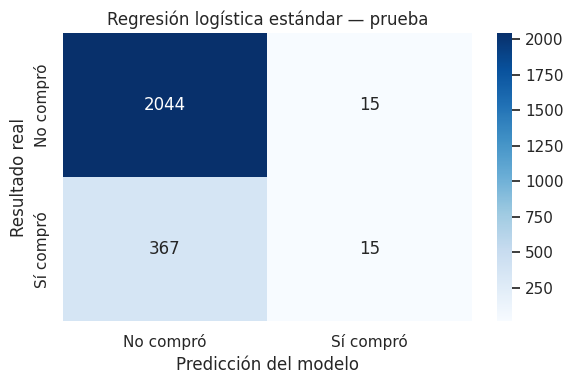

In [8]:
def mostrar_evaluacion(y_real, y_predicho, titulo):
    print('===', titulo, '===')
    print(classification_report(
        y_real, y_predicho,
        labels=[0, 1],
        target_names=['No compró', 'Sí compró'],
        zero_division=0
    ))

    matriz = confusion_matrix(y_real, y_predicho, labels=[0, 1])
    print('Matriz de confusión:')
    print(matriz)
    tn, fp, fn, tp = matriz.ravel()
    print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        matriz, annot=True, fmt='d', cmap='Blues',
        xticklabels=['No compró', 'Sí compró'],
        yticklabels=['No compró', 'Sí compró']
    )
    plt.xlabel('Predicción del modelo')
    plt.ylabel('Resultado real')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

mostrar_evaluacion(Y_test, Y_pred_test, 'Regresión logística estándar — prueba')

### Calcular las métricas por separado

**Accuracy** mide el porcentaje total de predicciones correctas; **Precision** mide la proporción de compras correctas entre las compras predichas; **Recall** mide cuántas compras reales logramos detectar; y **F1** resume Precision y Recall.

Como hay muchas más sesiones sin compra que con compra, **un Accuracy alto no es suficiente** para demostrar que el modelo detecta bien las compras.

In [9]:
def obtener_metricas(nombre, conjunto, y_real, y_predicho):
    return {
        'Modelo': nombre,
        'Conjunto': conjunto,
        'Accuracy': accuracy_score(y_real, y_predicho),
        'Precision': precision_score(y_real, y_predicho, zero_division=0),
        'Recall': recall_score(y_real, y_predicho, zero_division=0),
        'F1': f1_score(y_real, y_predicho, zero_division=0)
    }

resultados = [
    obtener_metricas('Regresión logística estándar', 'Entrenamiento', Y_train, Y_pred_train),
    obtener_metricas('Regresión logística estándar', 'Prueba', Y_test, Y_pred_test)
]

df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(4))

,Modelo,Conjunto,Accuracy,Precision,Recall,F1
0,Regresión logística estándar,Entrenamiento,0.8443,0.5349,0.0301,0.0571
1,Regresión logística estándar,Prueba,0.8435,0.5000,0.0393,0.0728


## Prueba con ponderacion de clases


Aquí probaremos **otra configuración del mismo algoritmo**, con `class_weight='balanced'`.

- La configuración estándar puede obtener buen Accuracy al predecir mayoritariamente «No compró».
- La configuración balanceada penaliza relativamente más los errores en la clase minoritaria.
- Es posible que **suba Recall**, pero también que aumenten los **falsos positivos** y disminuya Precision.

Este ejemplo nos sirve para comprender la dificultad del problema.

=== Regresión logística balanceada — prueba ===
              precision    recall  f1-score   support

   No compró       0.94      0.63      0.75      2059
   Sí compró       0.28      0.78      0.41       382

    accuracy                           0.65      2441
   macro avg       0.61      0.70      0.58      2441
weighted avg       0.84      0.65      0.70      2441

Matriz de confusión:
[[1287  772]
 [  83  299]]
TN=1287, FP=772, FN=83, TP=299


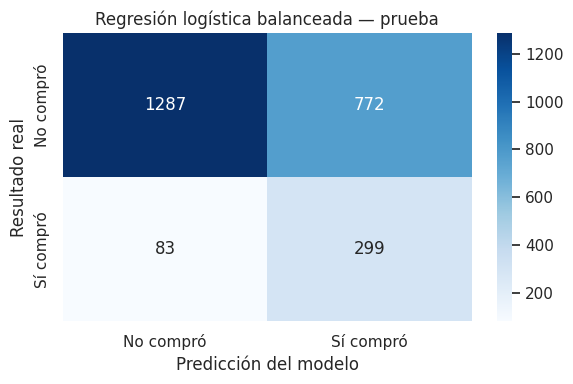

,Modelo,Conjunto,Accuracy,Precision,Recall,F1
0,Regresión logística estándar,Entrenamiento,0.8443,0.5349,0.0301,0.0571
1,Regresión logística estándar,Prueba,0.8435,0.5000,0.0393,0.0728
2,Regresión logística balanceada,Entrenamiento,0.6472,0.2713,0.7457,0.3978
3,Regresión logística balanceada,Prueba,0.6497,0.2792,0.7827,0.4116


In [10]:
lg_balanceada = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight='balanced'
)
lg_balanceada.fit(X_train_scaled, Y_train)

Y_pred_train_bal = lg_balanceada.predict(X_train_scaled)
Y_pred_test_bal = lg_balanceada.predict(X_test_scaled)

mostrar_evaluacion(Y_test, Y_pred_test_bal, 'Regresión logística balanceada — prueba')

resultados.extend([
    obtener_metricas('Regresión logística balanceada', 'Entrenamiento', Y_train, Y_pred_train_bal),
    obtener_metricas('Regresión logística balanceada', 'Prueba', Y_test, Y_pred_test_bal)
])

df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(4))

### Comparación de ambas configuraciones

Para facilitar la exposición, dejamos una tabla con porcentajes y cantidades de falsas alarmas y compras omitidas en **prueba**. Esta comparación es descriptiva.



In [11]:
comparacion = df_resultados[df_resultados['Conjunto'] == 'Prueba'].copy()
for metrica in ['Accuracy', 'Precision', 'Recall', 'F1']:
    comparacion[metrica] = (comparacion[metrica] * 100).round(2)

comparacion['Falsos positivos'] = [
    confusion_matrix(Y_test, Y_pred_test, labels=[0, 1])[0, 1],
    confusion_matrix(Y_test, Y_pred_test_bal, labels=[0, 1])[0, 1]
]
comparacion['Falsos negativos'] = [
    confusion_matrix(Y_test, Y_pred_test, labels=[0, 1])[1, 0],
    confusion_matrix(Y_test, Y_pred_test_bal, labels=[0, 1])[1, 0]
]

display(comparacion)

,Modelo,Conjunto,Accuracy,Precision,Recall,F1,Falsos positivos,Falsos negativos
1,Regresión logística estándar,Prueba,84.35,50.00,3.93,7.28,15,367
3,Regresión logística balanceada,Prueba,64.97,27.92,78.27,41.16,772,83


## Cambio de umbral de 0.50 a 0.70

In [12]:
# 1. Obtener las probabilidades de compra de ambos modelos
prob_estandar = lg.predict_proba(X_test_scaled)[:, 1]
prob_balanceada = lg_balanceada.predict_proba(X_test_scaled)[:, 1]

# 2. Crear predicciones con el umbral que propusimos
umbral_nuevo = 0.70
Y_pred_test_070 = (prob_estandar >= umbral_nuevo).astype(int)
Y_pred_test_bal_070 = (prob_balanceada >= umbral_nuevo).astype(int)

print('Umbral elegido para este experimento:', umbral_nuevo)
print('Ejemplo de probabilidades y decisiones:')
display(pd.DataFrame({
    'Probabilidad_balanceada': prob_balanceada[:8],
    'Prediccion_con_050': Y_pred_test_bal[:8],
    'Prediccion_con_070': Y_pred_test_bal_070[:8]
}).round(3))

Umbral elegido para este experimento: 0.7
Ejemplo de probabilidades y decisiones:


,Probabilidad_balanceada,Prediccion_con_050,Prediccion_con_070
0,0.537,1,0
1,0.802,1,1
2,0.542,1,0
3,0.463,0,0
4,0.009,0,0
5,0.913,1,1
6,0.026,0,0
7,0.351,0,0


### Matrices de confusión con umbral 0.70

Las filas indican las clases reales y las columnas las clases predichas. Compara sobre todo:
- **FP**: predecimos una compra que no ocurrió (falsa alarma).
- **FN**: no detectamos una compra que sí ocurrió (compra omitida).

Cuando aumentamos el umbral, suele haber menos predicciones positivas: es frecuente que disminuyan los FP, pero aumenten los FN.

=== Regresión logística estándar — umbral 0.70 ===
              precision    recall  f1-score   support

   No compró       0.84      1.00      0.92      2059
   Sí compró       1.00      0.00      0.01       382

    accuracy                           0.84      2441
   macro avg       0.92      0.50      0.46      2441
weighted avg       0.87      0.84      0.77      2441

Matriz de confusión:
[[2059    0]
 [ 381    1]]
TN=2059, FP=0, FN=381, TP=1


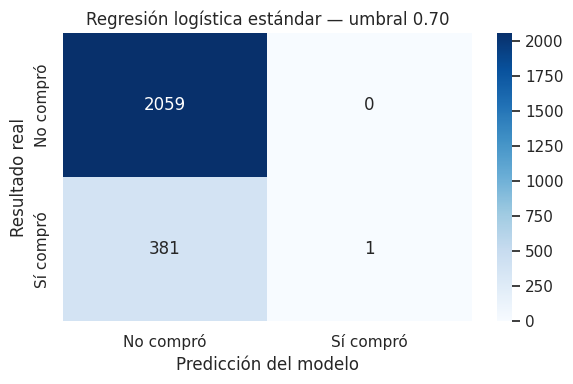

=== Regresión logística balanceada — umbral 0.70 ===
              precision    recall  f1-score   support

   No compró       0.88      0.89      0.88      2059
   Sí compró       0.35      0.32      0.34       382

    accuracy                           0.80      2441
   macro avg       0.61      0.61      0.61      2441
weighted avg       0.79      0.80      0.80      2441

Matriz de confusión:
[[1831  228]
 [ 258  124]]
TN=1831, FP=228, FN=258, TP=124


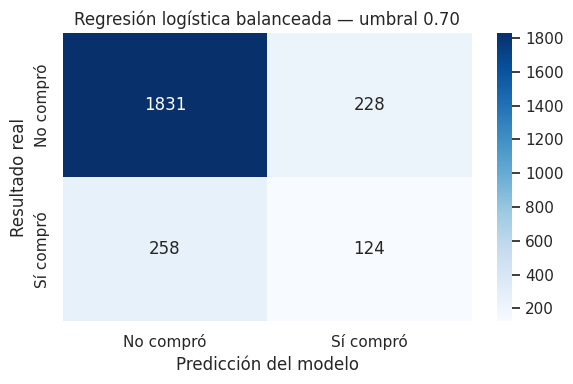

In [13]:
mostrar_evaluacion(Y_test, Y_pred_test_070,
                   'Regresión logística estándar — umbral 0.70')
mostrar_evaluacion(Y_test, Y_pred_test_bal_070,
                   'Regresión logística balanceada — umbral 0.70')

### Tabla para comparar 0.50 y 0.70

Usamos la misma función `obtener_metricas()` que en el resto del proyecto. Así no cambiamos la forma de medir el desempeño al cambiar el umbral.

In [14]:
def fila_evaluacion_umbral(nombre, prob_compra, umbral):
    # Convertir probabilidades a clases usando el umbral propuesto
    y_pred = (prob_compra >= umbral).astype(int)
    # Calcular las métricas que ya utilizamos en el ejercicio del profesor
    fila = obtener_metricas(nombre, 'Prueba', Y_test, y_pred)
    tn, fp, fn, tp = confusion_matrix(Y_test, y_pred, labels=[0, 1]).ravel()
    fila['Umbral'] = umbral
    fila['TP'] = tp
    fila['FP'] = fp
    fila['FN'] = fn
    fila['TN'] = tn
    return fila

filas_umbrales = []
for nombre, probabilidades_modelo in [
    ('Regresión logística estándar', prob_estandar),
    ('Regresión logística balanceada', prob_balanceada)
]:
    for umbral in [0.50, 0.70]:
        filas_umbrales.append(fila_evaluacion_umbral(
            nombre, probabilidades_modelo, umbral))

df_umbrales = pd.DataFrame(filas_umbrales)
comparacion_umbrales = df_umbrales.copy()
for metrica in ['Accuracy', 'Precision', 'Recall', 'F1']:
    comparacion_umbrales[metrica] = (comparacion_umbrales[metrica] * 100).round(2)
display(comparacion_umbrales[
    ['Modelo', 'Umbral', 'Accuracy', 'Precision', 'Recall', 'F1', 'TP', 'FP', 'FN', 'TN']
])

,Modelo,Umbral,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,Regresión logística estándar,0.5,84.35,50.00,3.93,7.28,15,15,367,2044
1,Regresión logística estándar,0.7,84.39,100.00,0.26,0.52,1,0,381,2059
2,Regresión logística balanceada,0.5,64.97,27.92,78.27,41.16,299,772,83,1287
3,Regresión logística balanceada,0.7,80.09,35.23,32.46,33.79,124,228,258,1831


### Gráfica comparativa de métricas con ambas decisiones

La gráfica siguiente permite observar el intercambio entre Precision y Recall. Un umbral mayor hace que el modelo exija más evidencia para predecir compras, pero **no garantiza un F1 más alto ni una mejor detección de compras**.

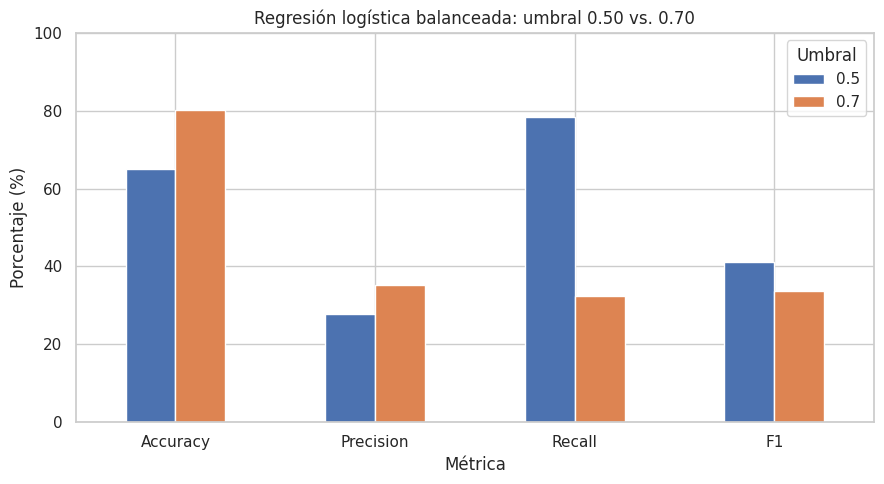

In [15]:
# Comparar solamente el modelo balanceado para que la gráfica sea fácil de exponer
balanceada_umbrales = comparacion_umbrales[
    comparacion_umbrales['Modelo'] == 'Regresión logística balanceada'
].copy()

balanceada_umbrales.set_index('Umbral')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].T.plot(kind='bar', figsize=(9, 5))
plt.title('Regresión logística balanceada: umbral 0.50 vs. 0.70')
plt.xlabel('Métrica')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Umbral')
plt.tight_layout()
plt.show()

### Coeficientes de regresión logística

Un coeficiente **positivo** se asocia, manteniendo las demás variables constantes.
Mostramos solo las variables numéricas originales de la configuración estándar, que estandarizamos y se pueden comparar en la misma escala. **Esto no demuestra causalidad** y no debe presentarse como una lista definitiva de las variables más importantes: hay variables correlacionadas y categorías codificadas que requieren cuidado al interpretarse.

,Variable,Coeficiente
7,ExitRates,-1.4744
8,SpecialDay,-0.1397
4,ProductRelated,-0.0752
1,Administrative_Duration,-0.0525
3,Informational_Duration,0.0051
2,Informational,0.0379
0,Administrative,0.0945
5,ProductRelated_Duration,0.1759
6,BounceRates,0.3472


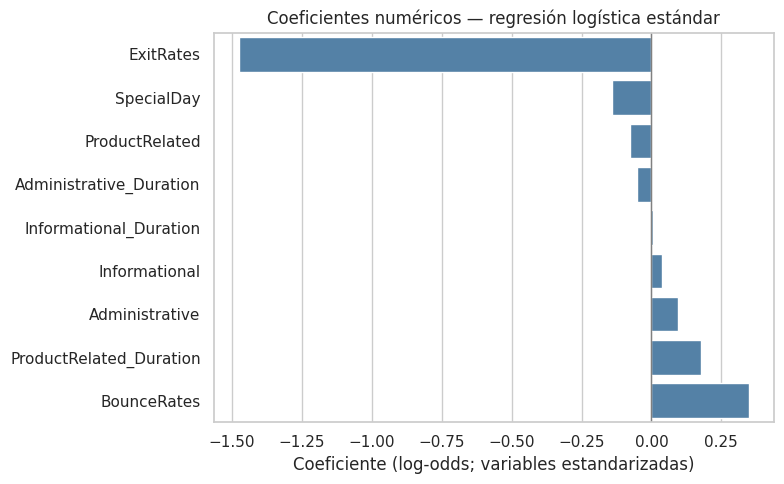

In [17]:
coeficientes = pd.DataFrame({
    'Variable': X_train_scaled.columns,
    'Coeficiente': lg.coef_[0]
})
coeficientes_numericos = coeficientes[
    coeficientes['Variable'].isin(variables_numericas)
].sort_values('Coeficiente')

display(coeficientes_numericos.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=coeficientes_numericos, y='Variable', x='Coeficiente', color='steelblue')
plt.axvline(0, color='gray', linewidth=1)
plt.title('Coeficientes numéricos — regresión logística estándar')
plt.xlabel('Coeficiente (log-odds; variables estandarizadas)')
plt.ylabel('')
plt.tight_layout()
plt.show()